<!-- 2026.10.28 一致性修订：请 Restart Kernel & Run All。初始化会验证当前 embedding→特征→预测→概率；旧 niche 缓存不再复用，旧图输出已清空。Deployment 最佳模型用法保持不变。 -->


<!-- # Prostate Patient_1 H2 — pan-cancer Hist2Pheno (UNI2 A6)

UNI2 A6 uses a 14 px crop (7 µm after rescale to 0.5 µm/px). Run `demo_uni2_A6.sh`. Predictions go to `pred_uni2_A6_bestmlp_paired_v2_seed42`.


Erickson et al. *Nature* 2022. Patient_1 series **H2**: H2_1, H2_2, H2_5 (3 sections). StarDist nuclei, **no cell-type ground truth**.
Sample ids are `Patient_1__H2_*`. Predictions are the pan-cancer **cross-section** checkpoint `A6_l12_links_2` (L1 / L12 / L2), spatial k=8 mean, no gate. A6 keeps the A2 trunk and sets L12 CE = 2 and L2→L12 / L12→L1 NLL = 2 (fold 1; pooled OOF L2 macro AUROC 0.8882).

JPEG EXIF is 72 dpi and is not used. µm/px is the HEST-1k spot-spacing estimate, about **0.57–0.69**. UNI rescales by `mpp/0.5` so the 16 px crop is **8 µm**.

Patient_1 is split by series so each file stays small. The other series: `Pred_visual_prostate_patient1_H1.ipynb`, `_H2.ipynb`, `_V1.ipynb`. Patient_2 is `Pred_visual_prostate_patient2_{H1,…,V2}.ipynb`. Full-resolution PNGs stay in `data/Visium/Prostate/pred_uni2_A6_bestmlp_paired_v2_seed42/figures/`.

```bash
SAMPLE=Patient_1__H2 bash code/External_val/Prostate/demo_uni2_A6.sh predict
``` -->


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
# 2026.10.28, explicit checkout override / Farm 可设 HIST2PHENO_REPO
import os
if os.environ.get("HIST2PHENO_REPO"):
    REPO = Path(os.environ["HIST2PHENO_REPO"]).expanduser().resolve()
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
import os
os.environ["UNI2_CKPT"] = str(REPO / "data/PanCancer/result_uni2_A6_l12_links_2_paired_v2_seed42/cross_dataset_cv/A6_l12_links_2/best_mlp_gpu.pt")
STAR_PROB_MIN = 0.0  # 2026.10.28, set above 0 to store a separate _probXX folder
import os as _prob_os
_prob_os.environ["STAR_PROB_MIN"] = "0" if float(STAR_PROB_MIN) <= 0 else f"{float(STAR_PROB_MIN):.2f}"
os.environ["UNI2_PRED_DIRNAME"] = "pred_uni2_A6_bestmlp_paired_v2_seed42"
sys.path.insert(0, str(REPO / "code" / "External_val" / "Prostate"))

import prostate_external as prostate_ext
prostate_ext.use_embedder("uni2")
PRED_ROOT = prostate_ext.PRED_ROOT
composition_table = prostate_ext.composition_table
discover_samples = prostate_ext.discover_samples
geometry = prostate_ext.geometry
sample_paths = prostate_ext.sample_paths
ensure_l2_probs = prostate_ext.ensure_l2_probs
plot_spatial = prostate_ext.plot_spatial
plot_composition = prostate_ext.plot_composition

PATIENT = "Patient_1"
SERIES = "H2"
group = discover_samples(f"{PATIENT}__{SERIES}")
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
# Re-run the plot cell after changing these. Notebook display uses DPI; saved PNGs use SAVE_DPI.
SAVE_FIGURES = False
FIGSIZE = (17.2, 6.6)
DPI = 160
SAVE_DPI = 300
HE_MAX_SIDE = 1400
MARKER_PX = 1.2
print(f"{PATIENT} {SERIES}  n={len(group)}")
for sample in group:
    g = geometry(sample)
    section = sample.split("__", 1)[-1]
    print(
        f"{section}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native14={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}  ({g['mpp_source']})"
    )
    pth = sample_paths(sample)
    print(f"  pred exists: {pth['pred'].is_file()}  {pth['pred']}")

# 2026.10.28, mandatory current-input preflight / 后续直接读 h5ad 的图表也不得绕过上游
import os as _pipeline_os
_pipeline_os.environ["STAR_PROB_MIN"] = str(globals().get("STAR_PROB_MIN", 0.0))
if "ensure_l2_probs" in globals():
    _owner = ensure_l2_probs.__self__
    _current_samples = list(group)
    _owner.cmd_predict(_current_samples, force=False, allow_cpu=True)
elif "ue" in globals():
    ue.cmd_predict(COHORT, samples, cuda_device=_pipeline_os.environ.get("CUDA_DEVICE", "0"),
                   force=False, allow_cpu=True, embedder=EMBEDDER)
else:
    raise RuntimeError("No current prediction validator; run the setup cell first")


Patient_1 H2  n=3
H2_1  mpp=0.5735 µm/px  native14=8.03 µm  after rescale=7.0 µm  scale=1.1470  (Visium scalefactors H2_1 (65 µm / spot_diameter_fullres=113.3410 px))
  pred exists: True  /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_uni2_A6_bestmlp_paired_v2_seed42/Patient_1__H2_1/Patient_1__H2_1_stardist_pred.h5ad
H2_2  mpp=0.5732 µm/px  native14=8.03 µm  after rescale=7.0 µm  scale=1.1465  (Visium scalefactors H2_2 (65 µm / spot_diameter_fullres=113.3889 px))
  pred exists: True  /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_uni2_A6_bestmlp_paired_v2_seed42/Patient_1__H2_2/Patient_1__H2_2_stardist_pred.h5ad
H2_5  mpp=0.5716 µm/px  native14=8.00 µm  after rescale=7.0 µm  scale=1.1431  (Visium scalefactors H2_5 (65 µm / spot_diameter_fullres=113.7250 px))
  pred exists: True  /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_uni2_A6_bestmlp_paired_v2_seed42/Patient_1__H2_5/Patient_1__H2_5_stardist_pred.h5ad
Loading best mod

In [2]:
# missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
# if missing:
#     raise FileNotFoundError(
#         f"No predictions yet for {PATIENT} {SERIES}: "
#         + ", ".join(s.split("__", 1)[-1] for s in missing)
#         + f". Run: SAMPLE={PATIENT}__{SERIES} bash code/External_val/Prostate/demo_uni2_A6.sh predict"
#     )

# display(Markdown(f"## {PATIENT} {SERIES} — spatial labels"))
# for fig in plot_spatial(
#     group,
#     figsize=FIGSIZE,
#     dpi=DPI,
#     he_max_side=HE_MAX_SIDE,
#     marker_px=MARKER_PX,
#     save=SAVE_FIGURES,
#     save_dpi=SAVE_DPI,
# ):
#     display(fig)
#     plt.close(fig)


## Patient_1 H2_5 — spatial labels

[plot] Patient_1__H2_5  nuclei=358,561  neighbor=11.7px  figsize=(17.2, 12.54)  dpi=160  marker_px=0.8  rows=HE+points
[plot] /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_uni2_A6_bestmlp_paired_v2_seed42/figures/Patient_1__H2_5_spatial_L1_L12_L2.pdf  save_dpi=300


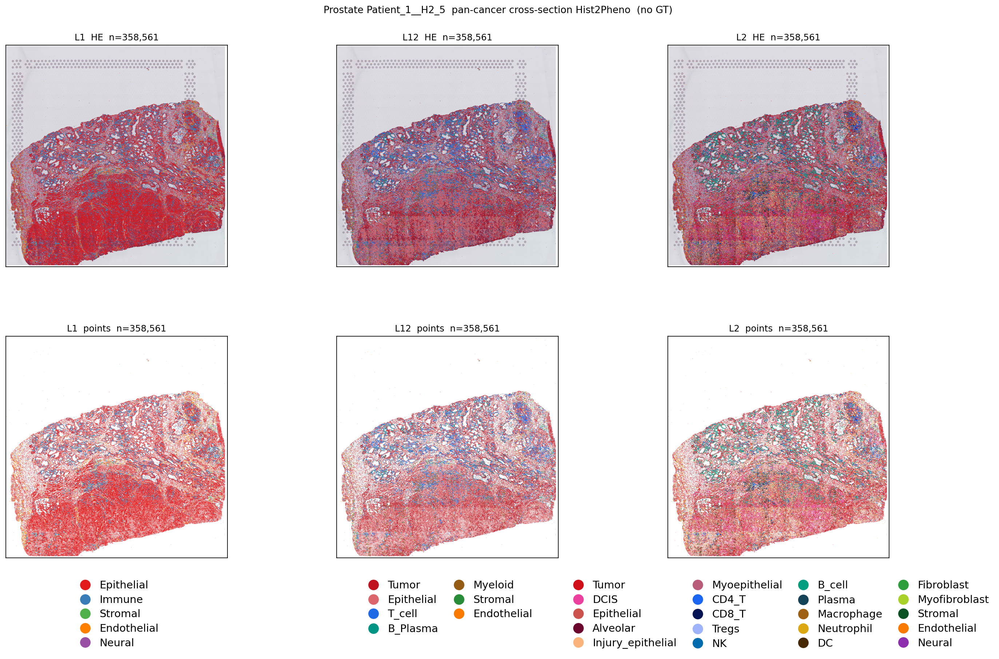

In [8]:
# # Only Patient_1__H2_5 (keep the cell above for the full H2 series)
# show = ["Patient_1__H2_5"]
# missing = [s for s in show if not sample_paths(s)["pred"].is_file()]
# if missing:
#     raise FileNotFoundError(
#         f"No predictions yet for {', '.join(missing)}. "
#         f"Run: SAMPLE=Patient_1__H2_5 bash code/External_val/Prostate/demo_uni2_A6.sh predict"
#     )


# SAVE_FIGURES = True
# MARKER_PX = 0.8
# display(Markdown("## Patient_1 H2_5 — spatial labels"))
# for fig in plot_spatial(
#     show,
#     figsize=FIGSIZE,
#     dpi=DPI,
#     he_max_side=HE_MAX_SIDE,
#     marker_px=MARKER_PX,
#     save=SAVE_FIGURES,
#     save_dpi=SAVE_DPI,
# ):
#     display(fig)
#     plt.close(fig)


<!-- ## Patient_1 H2_5 — composition and zoom

Whole-slide L1 / L12 / L2 fractions first (the full-slide maps look similar because the hues stay in the same family). Then a **1.4 mm** window on the lower-left tissue that mixes B / endothelium / fibroblast / T / tumour, so the three heads are readable. -->


Patient_1__H2_5  whole n=358,561  zoom [5250:7650]×[7900:10300]  1372×1372 µm  nuclei=14,758

===== Patient_1__H2_5 L1  whole slide =====


,class,n,fraction,mean_conf
0,Epithelial,281966,0.786,0.790
1,Immune,58720,0.164,0.608
2,Endothelial,13044,0.036,0.441
3,Neural,2559,0.007,0.477
4,Stromal,2272,0.006,0.405



===== Patient_1__H2_5 L12  whole slide =====


,class,n,fraction,mean_conf
5,Tumor,134971,0.376,0.653
6,Epithelial,130600,0.364,0.683
7,T_cell,56655,0.158,0.455
8,B_Plasma,15961,0.045,0.439
9,Myeloid,11215,0.031,0.376
10,Stromal,5338,0.015,0.330
11,Endothelial,3821,0.011,0.326



===== Patient_1__H2_5 L2  whole slide =====


,class,n,fraction,mean_conf
12,Tumor,119643,0.334,0.520
13,Epithelial,80183,0.224,0.440
14,B_cell,39185,0.109,0.381
15,Injury_epithelial,33450,0.093,0.457
16,DCIS,26769,0.075,0.519
17,CD4_T,17052,0.048,0.288
18,CD8_T,16524,0.046,0.272
19,Endothelial,10575,0.029,0.270
20,DC,7192,0.020,0.302
21,Myoepithelial,3163,0.009,0.345


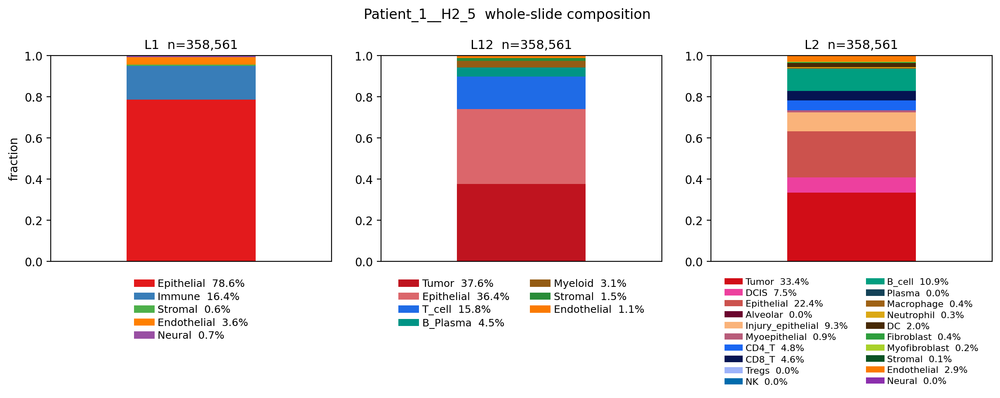

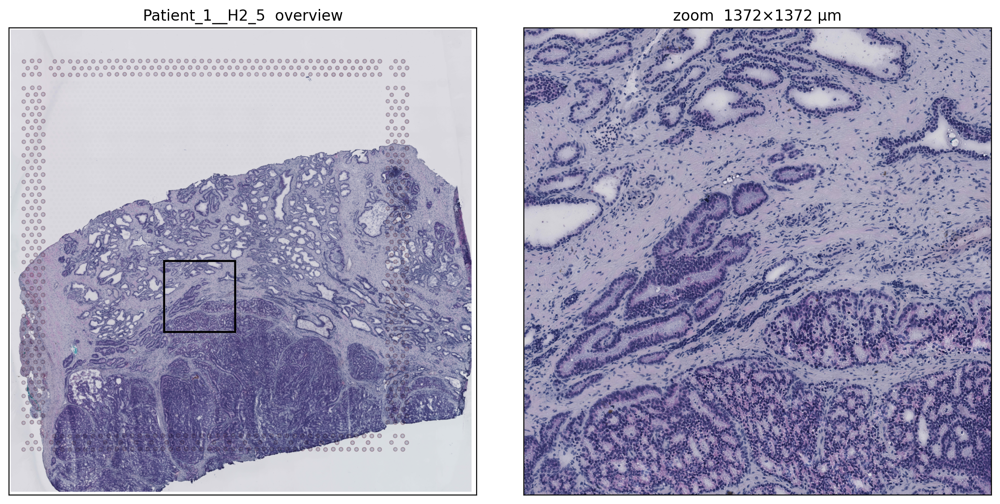

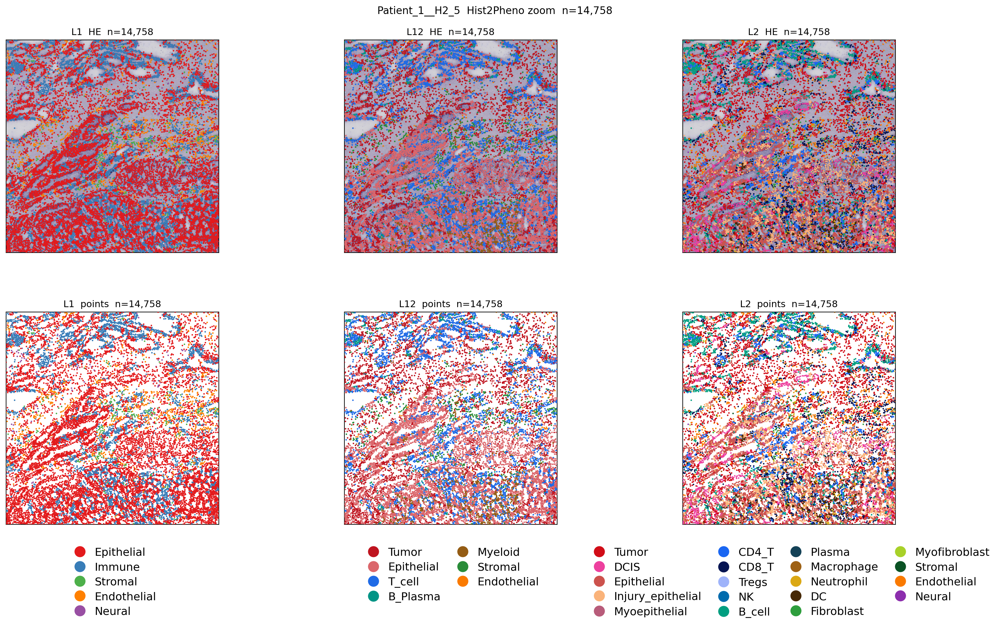

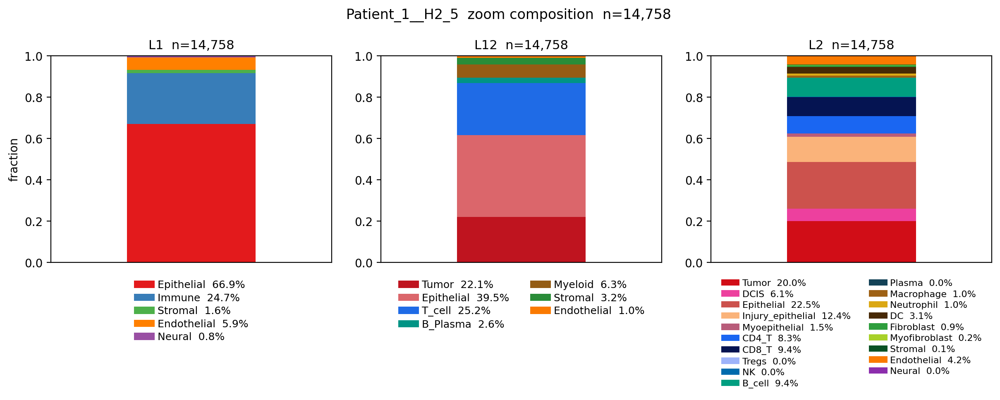

,head,class,n,fraction
0,L1,Epithelial,9880,0.669
1,L1,Immune,3645,0.247
2,L1,Stromal,234,0.016
3,L1,Endothelial,876,0.059
4,L1,Neural,123,0.008
5,L12,Tumor,3259,0.221
6,L12,Epithelial,5829,0.395
7,L12,T_cell,3724,0.252
8,L12,B_Plasma,387,0.026
9,L12,Myeloid,932,0.063


In [4]:
import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Rectangle

from Hist2Pheno_pkg.panel_figures import (
    crop_he_rectangle,
    nuclei_in_rectangle,
    plot_pred_composition_stacked,
    plot_roi_pred_spatial,
)
from prostate_external import COHORT

mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

SAMPLE_H25 = "Patient_1__H2_5"
# Native HE pixels. Same 2400 px (~1.38 mm) window shifted one box to the right.
ROI_X0, ROI_Y0, ROI_X1, ROI_Y1 = 5250, 7900, 7650, 10300
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
palettes = COHORT._palette()
paths = sample_paths(SAMPLE_H25)
pred = ad.read_h5ad(paths["pred"])
xy = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
mpp = float(geometry(SAMPLE_H25)["mpp_um"])
in_roi = nuclei_in_rectangle(xy, ROI_X0, ROI_Y0, ROI_X1, ROI_Y1)
w_um = (ROI_X1 - ROI_X0) * mpp
h_um = (ROI_Y1 - ROI_Y0) * mpp
print(
    f"{SAMPLE_H25}  whole n={pred.n_obs:,}  "
    f"zoom [{ROI_X0}:{ROI_X1}]×[{ROI_Y0}:{ROI_Y1}]  "
    f"{w_um:.0f}×{h_um:.0f} µm  nuclei={int(in_roi.sum()):,}"
)

comp = composition_table([SAMPLE_H25])
for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].sort_values("fraction", ascending=False)
    print(f"\n===== {SAMPLE_H25} {head}  whole slide =====")
    display(sub[["class", "n", "fraction", "mean_conf"]].round(3))

fig_bar, tab_bar = plot_pred_composition_stacked(
    pred.obs,
    palettes,
    dpi=max(int(DPI), 200),
    figsize=(12.4, 4.4),
    title=f"{SAMPLE_H25}  whole-slide composition",
    save_path=None,
    csv_path=(fig_dir / f"{SAMPLE_H25}_composition.csv") if SAVE_FIGURES else None,
)
if SAVE_FIGURES:
    for ext in (".png", ".pdf"):
        out = fig_dir / f"{SAMPLE_H25}_composition{ext}"
        fig_bar.savefig(out, bbox_inches="tight", facecolor="white", dpi=SAVE_DPI if ext == ".png" else None)
        print(out)
display(fig_bar)
plt.close(fig_bar)

thumb, full_w, full_h = COHORT._he_thumbnail(paths["he"], max_side=HE_MAX_SIDE)
he_roi = crop_he_rectangle(paths["he"], ROI_X0, ROI_Y0, ROI_X1, ROI_Y1)
fig_he, axes = plt.subplots(1, 2, figsize=(11.6, 5.6), dpi=max(int(DPI), 200))
axes[0].imshow(thumb, extent=(0, full_w, full_h, 0), interpolation="bilinear")
axes[0].add_patch(
    Rectangle(
        (ROI_X0, ROI_Y0), ROI_X1 - ROI_X0, ROI_Y1 - ROI_Y0,
        fill=False, edgecolor="black", linewidth=1.6,
    )
)
axes[0].set_title(f"{SAMPLE_H25}  overview")
axes[1].imshow(he_roi)
axes[1].set_title(f"zoom  {w_um:.0f}×{h_um:.0f} µm")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")
fig_he.tight_layout()
if SAVE_FIGURES:
    for ext in (".png", ".pdf"):
        out = fig_dir / f"{SAMPLE_H25}_ROI_HE{ext}"
        fig_he.savefig(out, bbox_inches="tight", facecolor="white", dpi=SAVE_DPI if ext == ".png" else None)
        print(out)
display(fig_he)
plt.close(fig_he)

fig_z, _ = plot_roi_pred_spatial(
    pred,
    paths["he"],
    x0=ROI_X0,
    y0=ROI_Y0,
    x1=ROI_X1,
    y1=ROI_Y1,
    palettes=palettes,
    in_roi=in_roi,
    marker_px=5.0,
    dpi=max(int(DPI), 200),
    figsize=(16.8, 11.2),
    title=f"{SAMPLE_H25}  Hist2Pheno zoom  n={int(in_roi.sum()):,}",
    save_path=None,
    save_dpi=SAVE_DPI,
)
if SAVE_FIGURES:
    for ext in (".png", ".pdf"):
        out = fig_dir / f"{SAMPLE_H25}_ROI_spatial_L1_L12_L2{ext}"
        fig_z.savefig(out, bbox_inches="tight", facecolor="white", dpi=1.5 * SAVE_DPI if ext == ".png" else None)
        print(out)
display(fig_z)
plt.close(fig_z)

fig_zbar, tab_zbar = plot_pred_composition_stacked(
    pred.obs.loc[in_roi],
    palettes,
    dpi=max(int(DPI), 200),
    figsize=(12.4, 4.4),
    title=f"{SAMPLE_H25}  zoom composition  n={int(in_roi.sum()):,}",
    save_path=None,
    csv_path=(fig_dir / f"{SAMPLE_H25}_ROI_composition.csv") if SAVE_FIGURES else None,
)
if SAVE_FIGURES:
    for ext in (".png", ".pdf"):
        out = fig_dir / f"{SAMPLE_H25}_ROI_composition{ext}"
        fig_zbar.savefig(out, bbox_inches="tight", facecolor="white", dpi=SAVE_DPI if ext == ".png" else None)
        print(out)
display(fig_zbar)
plt.close(fig_zbar)
display(tab_zbar.round(3))


In [5]:
# display(Markdown(f"## {PATIENT} {SERIES} — composition"))
# comp = composition_table(group)
# for head in ("L1", "L12", "L2"):
#     sub = comp.loc[comp["head"] == head].copy()
#     sub["section"] = sub["sample"].str.split("__").str[-1]
#     order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
#     wide = (
#         sub.pivot_table(index="class", columns="section", values=["fraction", "n", "mean_conf"])
#         .reindex(order)
#     )
#     print(f"\n===== {PATIENT} {SERIES} {head} =====")
#     display(wide.round(3))

# for fig in plot_composition(group, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI):
#     display(fig)
#     plt.close(fig)


<!-- ## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native JPEG pixels, so R = **55 µm** is converted with **that slide's** µm/px, not 0.5. TLS, SRI, and TNI each use a 1×3 row. Previews in this notebook are resized; the saved PNG is 300 dpi. -->


In [6]:
# import importlib

# for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
#     if str(_p) not in sys.path:
#         sys.path.insert(0, str(_p))

# import histology_niche_index as hni
# importlib.reload(hni)
# import histology_derived_niche_index as hdni
# importlib.reload(hdni)
# from histology_niche_index import OrganNicheConfig

# import anndata as ad

# TLS_RADIUS_UM = 55.0
# RECOMPUTE_NICHE = True  # 2026.10.28, legacy niche cache lacks provenance; recompute from verified current probabilities

# PROSTATE_NICHE = OrganNicheConfig(
#     pan_organ="pancancer_prostate",
#     tls_b=("B_cell", "Plasma"),
#     tls_t=("CD4_T", "CD8_T", "Tregs"),
#     tls_dc=("DC",),
#     epithelium=(
#         "Epithelial", "Tumor", "Alveolar",
#         "Injury_epithelial", "DCIS", "Myoepithelial",
#     ),
#     fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
#     endothelial=("Endothelial",),
#     macrophage=("Macrophage",),
#     um_per_he_pixel=float(geometry(group[0])["mpp_um"]),
#     spatial_radius_um=TLS_RADIUS_UM,
#     cohort="Prostate",
# )
# display(hni.index_formula_table(PROSTATE_NICHE))


In [7]:
# import numpy as np

# missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
# if missing:
#     raise FileNotFoundError(
#         f"No predictions yet for {PATIENT} {SERIES}: "
#         + ", ".join(s.split("__", 1)[-1] for s in missing)
#         + f". Run: SAMPLE={PATIENT}__{SERIES} bash code/External_val/Prostate/demo_uni2_A6.sh predict"
#     )
# display(Markdown(f"## {PATIENT} {SERIES} — TLS / SRI / TNI"))
# frames = {}
# for sample in group:
#     paths = sample_paths(sample)
#     niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
#     mpp = float(geometry(sample)["mpp_um"])
#     if niche_path.is_file() and not RECOMPUTE_NICHE:
#         cached = ad.read_h5ad(niche_path)
#         df = cached.obs.copy()
#         xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
#         df["coord_x"] = xy[:, 0]
#         df["coord_y"] = xy[:, 1]
#         print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
#     else:
#         probs, class_names = ensure_l2_probs(sample)
#         absent = hni.missing_index_cell_types(class_names, PROSTATE_NICHE)
#         if absent:
#             raise RuntimeError(f"{sample} missing niche compartments: {absent}")
#         pred = ad.read_h5ad(paths["pred"])
#         coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
#         df = pred.obs.copy()
#         df["coord_x"] = coords[:, 0]
#         df["coord_y"] = coords[:, 1]
#         df = hni.add_abundance_indices(df, probs, class_names, PROSTATE_NICHE)
#         df = hni.add_spatial_indices(
#             df, probs, class_names, coords, PROSTATE_NICHE,
#             radius_um=TLS_RADIUS_UM,
#             um_per_pixel=mpp,
#         )
#         out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
#         out.obsm["spatial_HE"] = coords
#         out.uns["tls_radius_um"] = TLS_RADIUS_UM
#         out.uns["um_per_px"] = mpp
#         __import__("pipeline_provenance").publish_derived_h5ad(out,niche_path,paths["pred"], probabilities=probs, class_names=class_names, obs_names=pred.obs_names, parameters={"config":PROSTATE_NICHE,"mpp":mpp,"radius_um":TLS_RADIUS_UM},algorithm=hni.__file__)
#         print(f"[niche] wrote {niche_path}  n={len(df):,}")
#     frames[sample] = df
#     print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
#     print(
#         f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
#         f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
#     )

# def tls_score_row(df, sample: str) -> dict:
#     a = df["idx_TLS"].to_numpy(dtype=float)
#     s = df["idx_TLS_spatial"].to_numpy(dtype=float)
#     a_hi = a >= np.percentile(a, 95)
#     s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
#     inter = int(np.logical_and(a_hi, s_hi).sum())
#     union = int(np.logical_or(a_hi, s_hi).sum())
#     n_a = int(a_hi.sum())
#     return {
#         "sample": sample,
#         "n": int(len(df)),
#         "TLS_mean": float(np.mean(a)),
#         "TLS_median": float(np.median(a)),
#         "TLS_p95": float(np.percentile(a, 95)),
#         "TLS_max": float(np.max(a)),
#         "TLS_spatial_mean": float(np.mean(s)),
#         "TLS_spatial_median": float(np.median(s)),
#         "TLS_spatial_p95": float(np.percentile(s, 95)),
#         "TLS_spatial_max": float(np.max(s)),
#         "pearson": float(np.corrcoef(a, s)[0, 1]),
#         "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
#         "top5_jaccard": (inter / union) if union else float("nan"),
#         "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
#         "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
#         "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
#     }

# tls_quant = pd.DataFrame([tls_score_row(df, sample) for sample, df in frames.items()])
# tls_quant.insert(1, "section", tls_quant["sample"].str.split("__").str[-1])
# tls_quant_path = fig_dir / f"tls_score_summary_{PATIENT}_{SERIES}.csv"
# tls_quant.to_csv(tls_quant_path, index=False)
# print(tls_quant_path)
# display(tls_quant.round(3))

# for sample, df in frames.items():
#     fig, axes = hdni.plot_tls_abundance_vs_spatial(
#         df,
#         sample,
#         radius_um=TLS_RADIUS_UM,
#         use_entropy=False,
#         split_spatial_candidates=True,
#         dpi=DPI,
#         save_dpi=SAVE_DPI,
#         point_size=0.15,
#         candidate_size=1.2,
#         save_path=(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png") if SAVE_FIGURES else None,
#     )
#     display(fig)
#     plt.close(fig)
#     for abundance_col, spatial_col, candidate_col, tag in (
#         ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
#         ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
#     ):
#         fig, axes = hdni.plot_tls_abundance_vs_spatial(
#             df,
#             sample,
#             radius_um=TLS_RADIUS_UM,
#             abundance_col=abundance_col,
#             spatial_col=spatial_col,
#             candidate_col=candidate_col,
#             score_name=tag,
#             use_entropy=False,
#             split_spatial_candidates=True,
#             dpi=DPI,
#             save_dpi=SAVE_DPI,
#             point_size=0.15,
#             candidate_size=1.2,
#             save_path=(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png") if SAVE_FIGURES else None,
#         )
#         display(fig)
#         plt.close(fig)
